# 0. 데이터 불러오기

In [80]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [81]:
import pandas as pd

train = pd.read_csv('/content/drive/MyDrive/[ESAA] OB 1조/프로젝트2/train.csv')
val = pd.read_csv('/content/drive/MyDrive/[ESAA] OB 1조/프로젝트2/val.csv')
test = pd.read_csv('/content/drive/MyDrive/[ESAA] OB 1조/프로젝트2/test.csv')
sample_submission = pd.read_csv('/content/drive/MyDrive/[ESAA] OB 1조/프로젝트2/sample_submission.csv')

#1. 데이터 이해

##1-1. 데이터 크기 및 컬럼 확인

In [82]:
print(train.shape)
print(val.shape)
print(test.shape)
print(sample_submission.shape)

(113842, 31)
(28462, 32)
(142503, 31)
(142503, 2)


In [83]:
print(train.columns)
print(val.columns)

Index(['ID', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30'],
      dtype='object')
Index(['ID', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30',
       'Class'],
      dtype='object')


##1-2. 데이터 타입 및 기본 정보 확인

In [84]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113842 entries, 0 to 113841
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      113842 non-null  int64  
 1   V1      113842 non-null  float64
 2   V2      113842 non-null  float64
 3   V3      113842 non-null  float64
 4   V4      113842 non-null  float64
 5   V5      113842 non-null  float64
 6   V6      113842 non-null  float64
 7   V7      113842 non-null  float64
 8   V8      113842 non-null  float64
 9   V9      113842 non-null  float64
 10  V10     113842 non-null  float64
 11  V11     113842 non-null  float64
 12  V12     113842 non-null  float64
 13  V13     113842 non-null  float64
 14  V14     113842 non-null  float64
 15  V15     113842 non-null  float64
 16  V16     113842 non-null  float64
 17  V17     113842 non-null  float64
 18  V18     113842 non-null  float64
 19  V19     113842 non-null  float64
 20  V20     113842 non-null  float64
 21  V21     11

In [85]:
val.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28462 entries, 0 to 28461
Data columns (total 32 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      28462 non-null  int64  
 1   V1      28462 non-null  float64
 2   V2      28462 non-null  float64
 3   V3      28462 non-null  float64
 4   V4      28462 non-null  float64
 5   V5      28462 non-null  float64
 6   V6      28462 non-null  float64
 7   V7      28462 non-null  float64
 8   V8      28462 non-null  float64
 9   V9      28462 non-null  float64
 10  V10     28462 non-null  float64
 11  V11     28462 non-null  float64
 12  V12     28462 non-null  float64
 13  V13     28462 non-null  float64
 14  V14     28462 non-null  float64
 15  V15     28462 non-null  float64
 16  V16     28462 non-null  float64
 17  V17     28462 non-null  float64
 18  V18     28462 non-null  float64
 19  V19     28462 non-null  float64
 20  V20     28462 non-null  float64
 21  V21     28462 non-null  float64
 22

In [86]:
train.dtypes

,0
ID,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


In [87]:
val['Class'].dtype

dtype('int64')

##1-3. 결측치 및 중복값 확인

In [88]:
print("train 결측치 수:", train.isnull().sum().sum())
print("val 결측치 수:", val.isnull().sum().sum())
print("test 결측치 수:", test.isnull().sum().sum())

train 결측치 수: 0
val 결측치 수: 0
test 결측치 수: 0


In [89]:
print("train 중복 행:", train.duplicated().sum())
print("val 중복 행:", val.duplicated().sum())
print("test 중복 행:", test.duplicated().sum())

train 중복 행: 0
val 중복 행: 0
test 중복 행: 0


In [90]:
feature_cols = [col for col in train.columns if col != 'ID']

print("train 특성 기준 중복:", train[feature_cols].duplicated().sum())

train 특성 기준 중복: 245


전체 행 기준 중복 데이터는 존재하지 않았으나, 거래 식별자인 ID를 제외한 V1~V30 기준으로 245개의 중복 행이 확인되었다. 서로 다른 거래에서 동일한 특성값이 나타날 가능성을 고려하여 현 단계에서는 제거하지 않았다.

#2. EDA

##2-1. 기술 통계량 확인

In [91]:
stats = train.drop(columns='ID').describe().T

stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,mean,std,min,25%,50%,75%,max
V1,1.972910e-04,1.951060,-56.407510,-0.923479,0.012074,1.315373,2.454930
V2,1.288795e-03,1.651064,-72.715728,-0.595602,0.066390,0.801687,21.467203
V3,9.717363e-03,1.496916,-32.454198,-0.883877,0.183868,1.037120,4.187811
V4,-4.169208e-03,1.412633,-5.600607,-0.853728,-0.019359,0.742208,16.491217
V5,4.749962e-04,1.367533,-42.147898,-0.689853,-0.054060,0.614214,34.801666
V6,5.141158e-03,1.330583,-26.160506,-0.766094,-0.272436,0.405285,23.917837
V7,5.769024e-03,1.204111,-41.506796,-0.552071,0.039036,0.568750,44.054461
V8,-2.450588e-03,1.185504,-50.943369,-0.209492,0.020970,0.328303,20.007208
V9,-2.107069e-03,1.095415,-13.434066,-0.647477,-0.052157,0.590705,10.392889
V10,5.209413e-03,1.071337,-24.403185,-0.533477,-0.090810,0.455287,15.331742


대부분의 변수는 평균과 중앙값이 0 부근에 위치하였으나, 일부 변수에서 최소·최대값이 사분위수 범위와 크게 떨어져 있는 것을 확인하였다. 특히 V29는 다른 변수에 비해 값의 범위와 표준편차가 크게 나타났다. 따라서 변수별 분포 및 이상값 존재 여부를 추가적으로 시각화하여 확인할 필요가 있다.

##2-2. 변수별 분포 확인

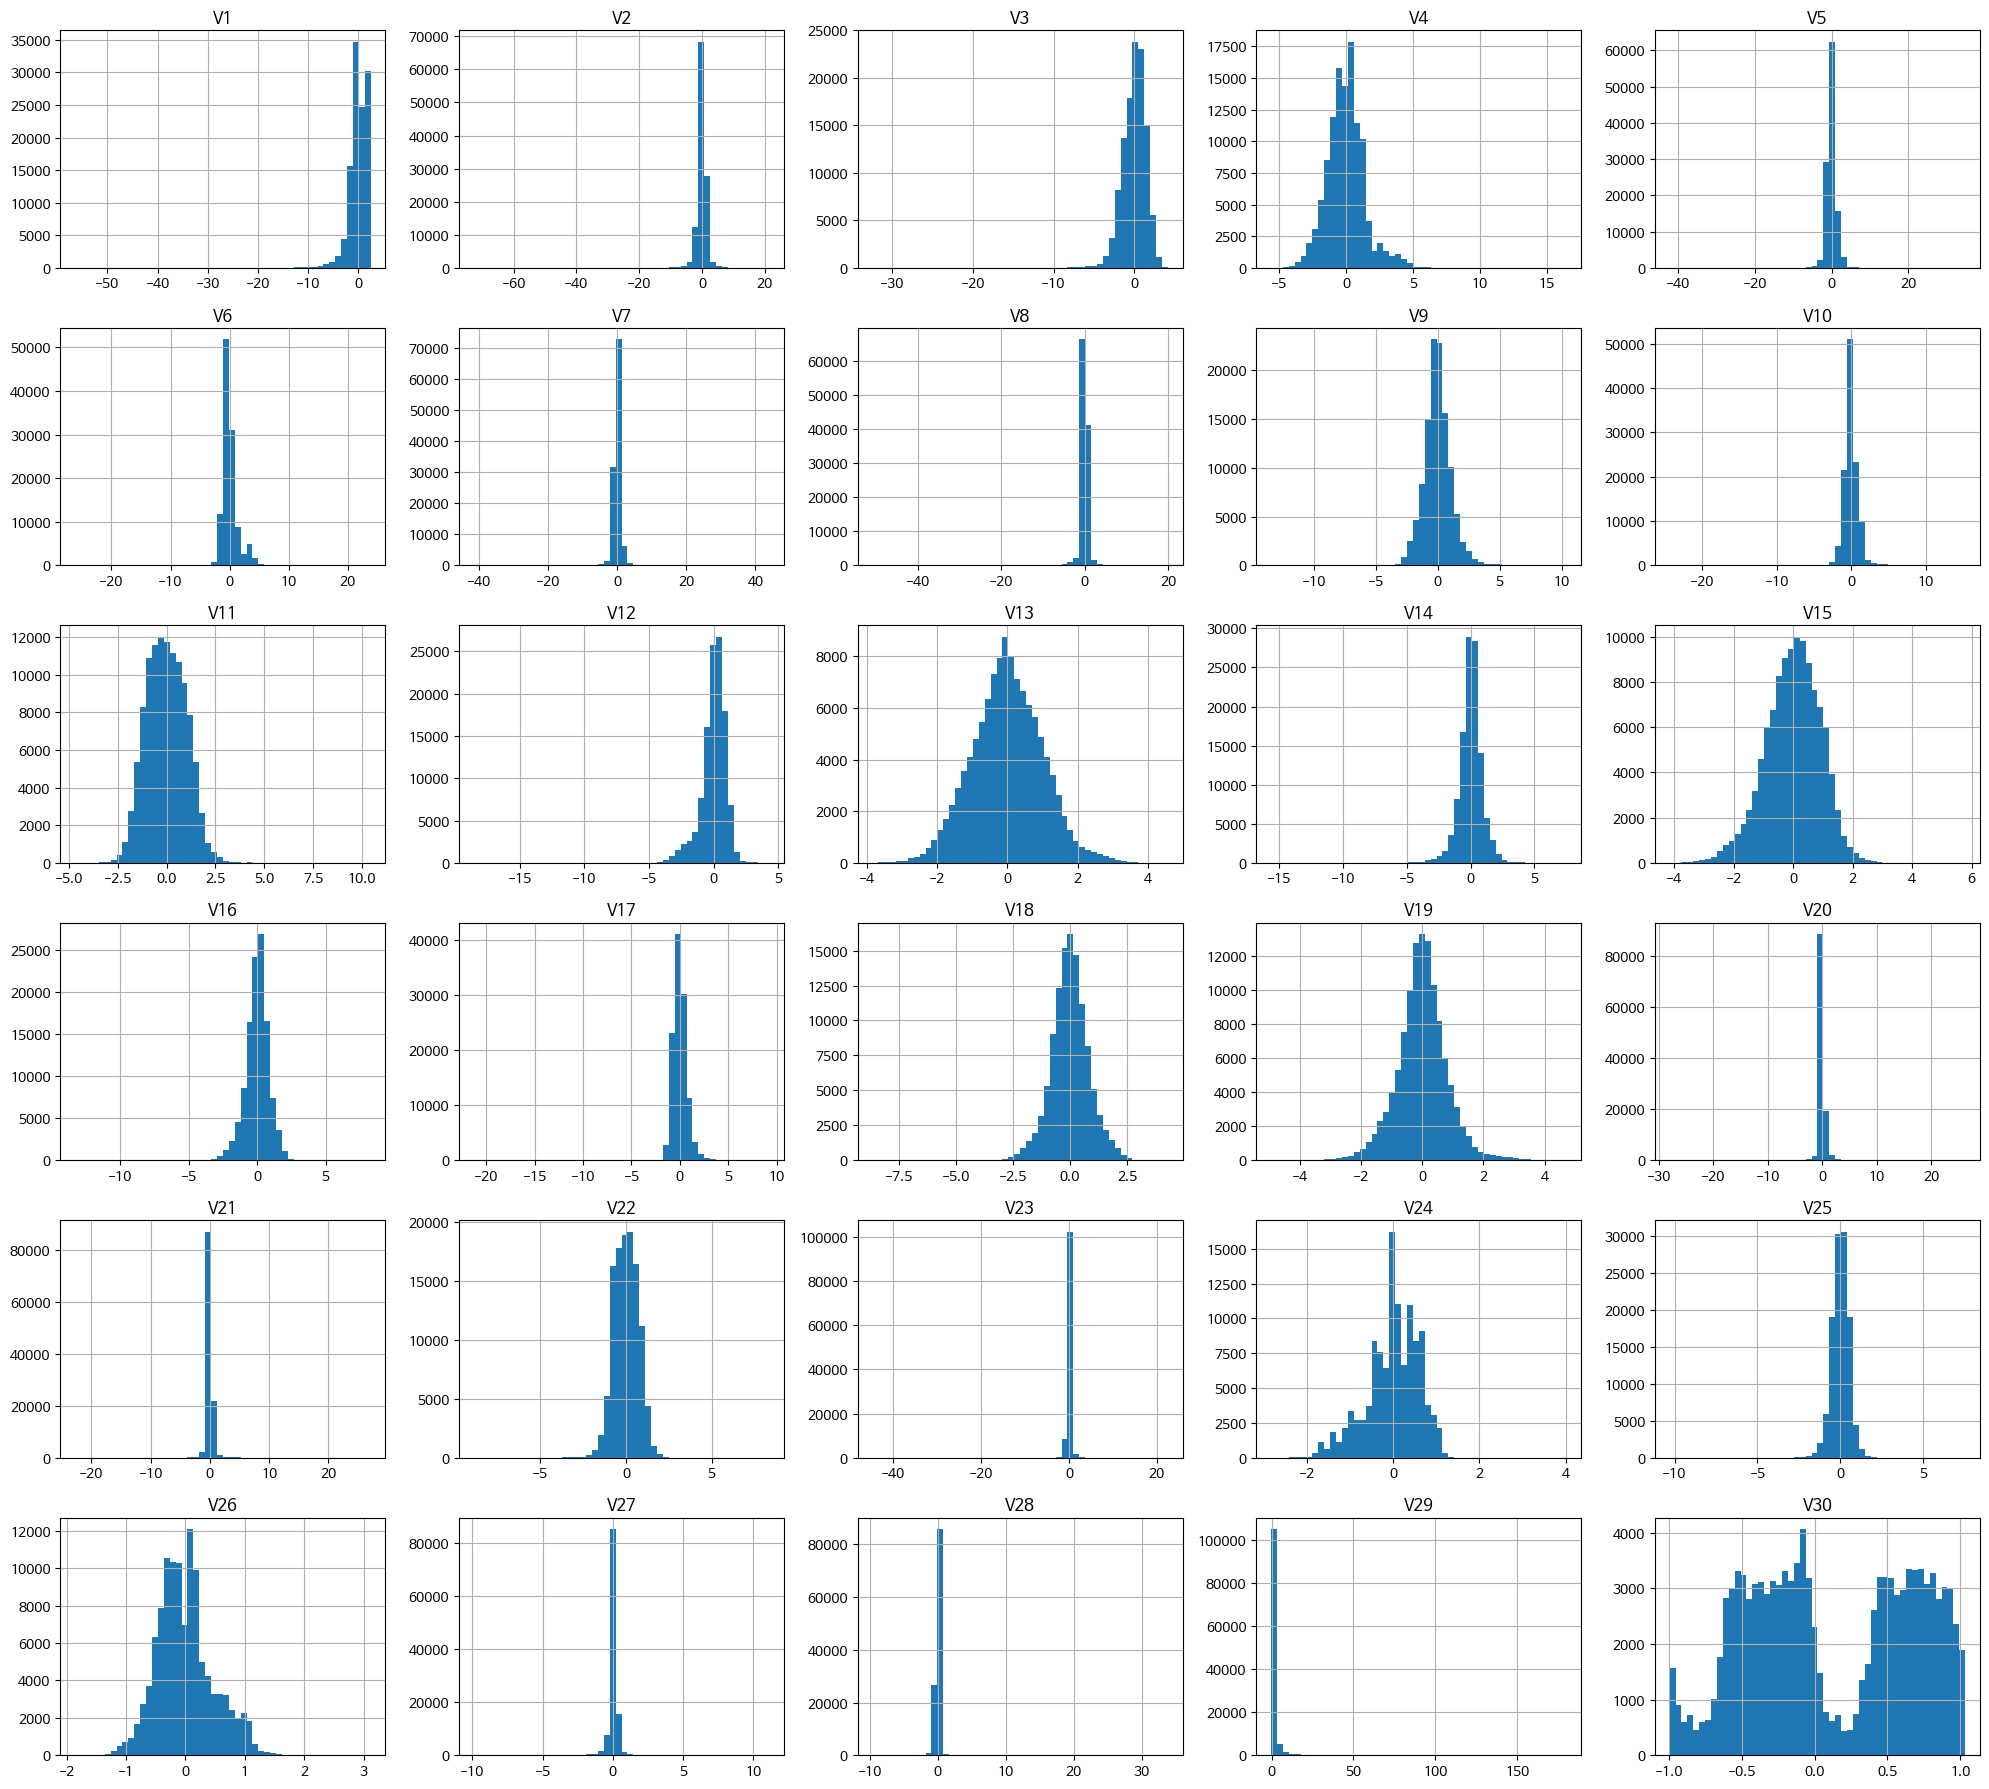

In [92]:
import matplotlib.pyplot as plt

features = [col for col in train.columns if col != 'ID']

train[features].hist(
    bins=50,
    figsize=(20, 18)
)

plt.tight_layout()
plt.show()

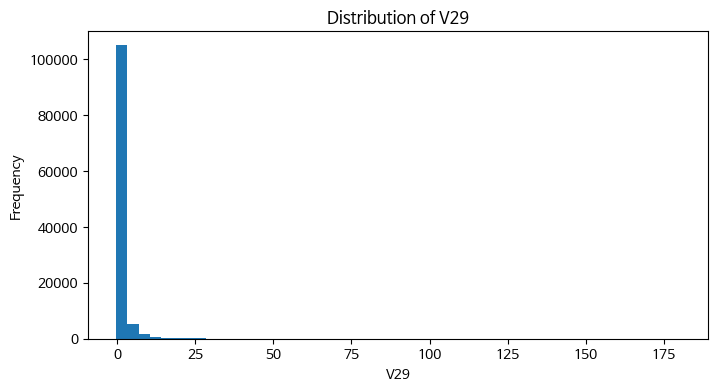

In [93]:
plt.figure(figsize=(8, 4))
plt.hist(train['V29'], bins=50)
plt.title('Distribution of V29')
plt.xlabel('V29')
plt.ylabel('Frequency')
plt.show()

변수별 히스토그램을 확인한 결과, 대부분의 변수는 0 부근에 값이 집중되어 있었으나 일부 변수에서는 긴 꼬리와 극단값이 확인되었다. 특히 V29는 대부분의 값이 낮은 구간에 집중된 반면 일부 큰 값이 존재하여 강한 오른쪽 치우침을 보였다. 또한 변수마다 분포 형태와 값의 범위가 상이하여 이후 모델링 단계에서 스케일 차이에 대한 고려가 필요할 것으로 판단하였다.

##2-3. Class 불균형 확인

In [94]:
class_counts = val['Class'].value_counts()
class_ratio = val['Class'].value_counts(normalize=True)

print(class_counts)
print(class_ratio)

Class
0    28432
1       30
Name: count, dtype: int64
Class
0    0.998946
1    0.001054
Name: proportion, dtype: float64


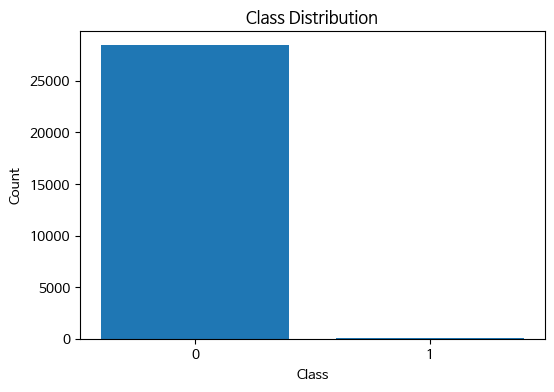

In [95]:
import matplotlib.pyplot as plt

class_counts = val['Class'].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)

plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')

plt.show()

Validation 데이터의 클래스 분포를 확인한 결과, 정상 거래는 28,432건으로 약 99.89%를 차지한 반면 사기 거래는 30건으로 약 0.11%에 불과하였다. 따라서 데이터가 매우 심한 클래스 불균형을 보이고 있음을 확인하였다. 이러한 경우 Accuracy만으로 모델 성능을 평가하면 정상 거래만 예측하는 모델도 높은 정확도를 얻을 수 있으므로, 이후 평가에서는 Precision, Recall, F1-score와 같은 지표를 함께 고려할 필요가 있다.

##2-4. 정상 거래와 사기 거래별 변수 비교

In [96]:
feature_cols = [col for col in val.columns if col not in ['ID', 'Class']]

class_mean = val.groupby('Class')[feature_cols].mean()

class_mean.T

Class,0,1
V1,0.011820,-6.490231
V2,-0.003034,4.786568
V3,0.011758,-9.802422
V4,-0.003865,5.458560
V5,0.000900,-4.617862
V6,-0.015812,-1.834732
V7,0.013685,-7.699301
V8,0.007648,1.312151
V9,-0.001409,-3.318254
V10,0.005692,-7.575105


In [97]:
mean_diff = abs(class_mean.loc[1] - class_mean.loc[0])

mean_diff.sort_values(ascending=False)

,0
V3,9.814180
V14,7.835667
V7,7.712986
V10,7.580796
V17,7.352987
V12,7.305109
V1,6.502051
V4,5.462425
V2,4.789603
V5,4.618762


정상 거래와 사기 거래의 변수별 평균을 비교한 결과, 일부 변수에서 두 클래스 간 뚜렷한 차이가 확인되었다. 특히 V3, V14, V7, V10, V17, V12, V1 등의 변수에서 평균 차이가 크게 나타났으며, 해당 변수들이 사기 거래를 구분하는 데 중요한 정보를 포함할 가능성이 있음을 확인하였다.

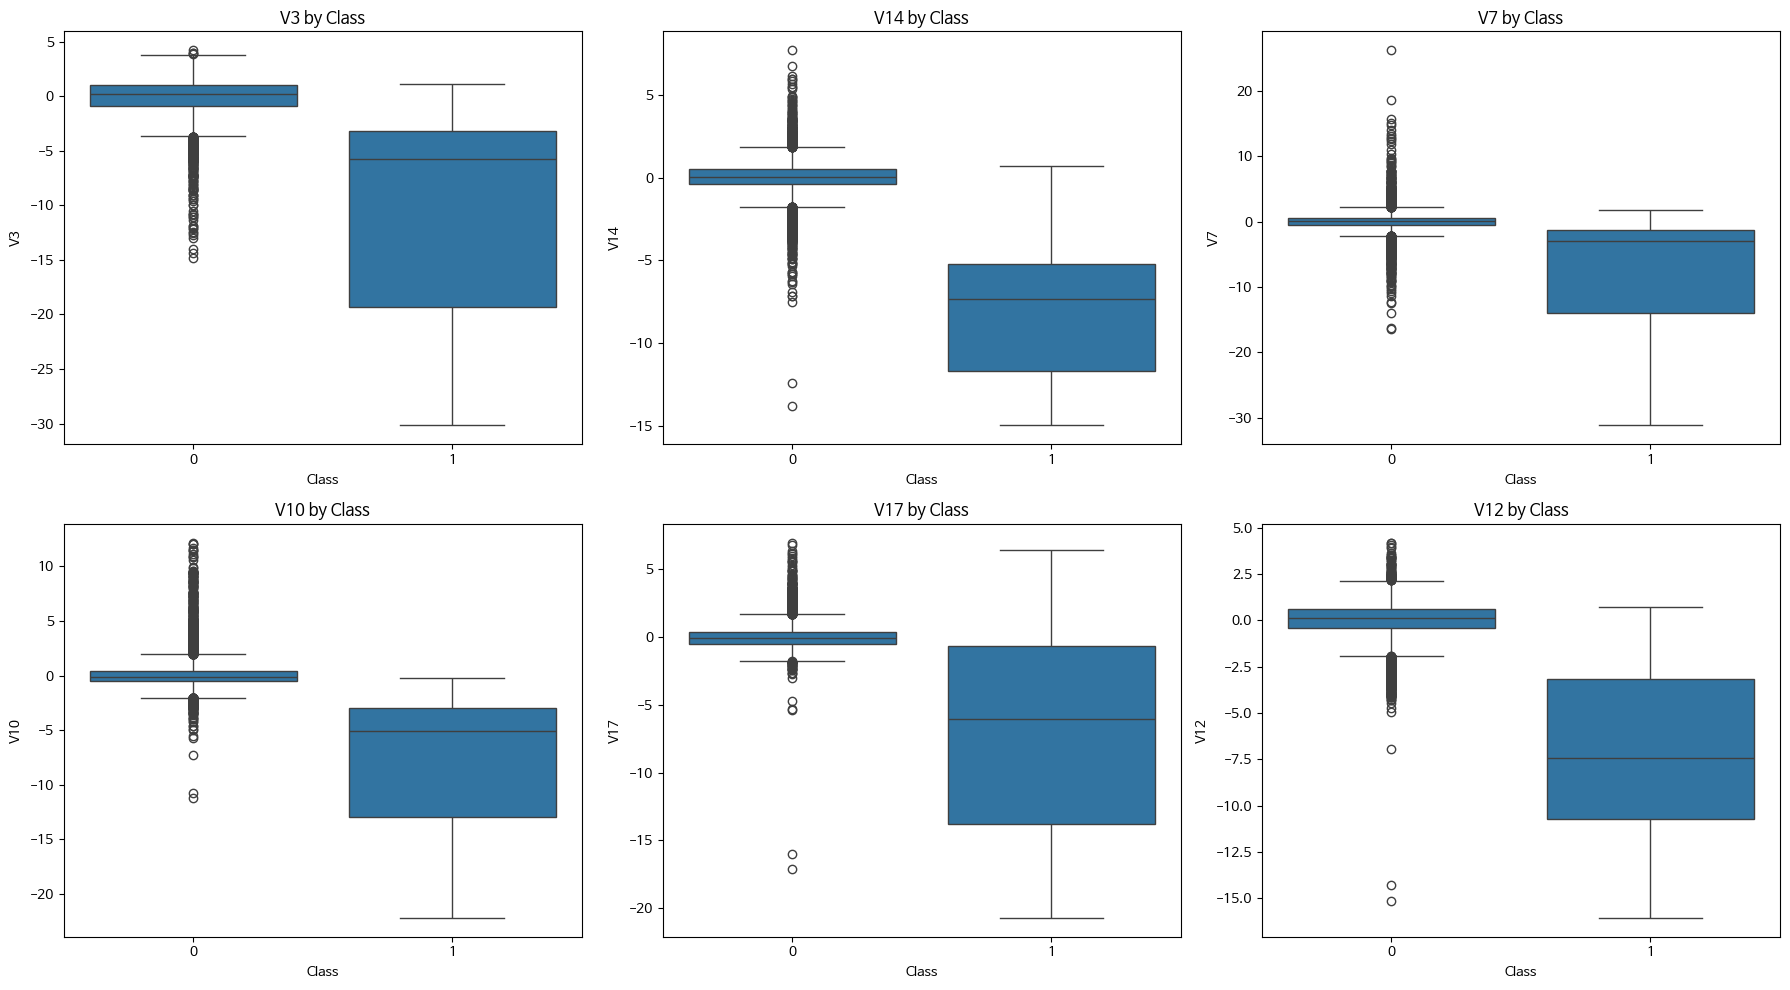

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = mean_diff.sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        data=val,
        x='Class',
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f'{feature} by Class')

plt.tight_layout()
plt.show()

평균 차이가 큰 상위 변수에 대해 클래스별 박스플롯을 비교한 결과, V3, V14, V7, V10, V17, V12에서 정상 거래와 사기 거래의 분포가 뚜렷하게 구분되는 경향을 확인하였다. 특히 사기 거래는 해당 변수들에서 정상 거래보다 전반적으로 낮은 값을 보였으며, 중앙값과 사분위 범위에도 차이가 나타났다. 따라서 이 변수들은 사기 거래 탐지에 유의미한 정보를 제공할 가능성이 있다. 단, 사기 거래 표본 수가 30건으로 매우 적기 때문에 해당 차이가 일반화되는지는 이후 모델링과 검증을 통해 확인할 필요가 있다.

##2-5. 변수 간 상관관계 분석

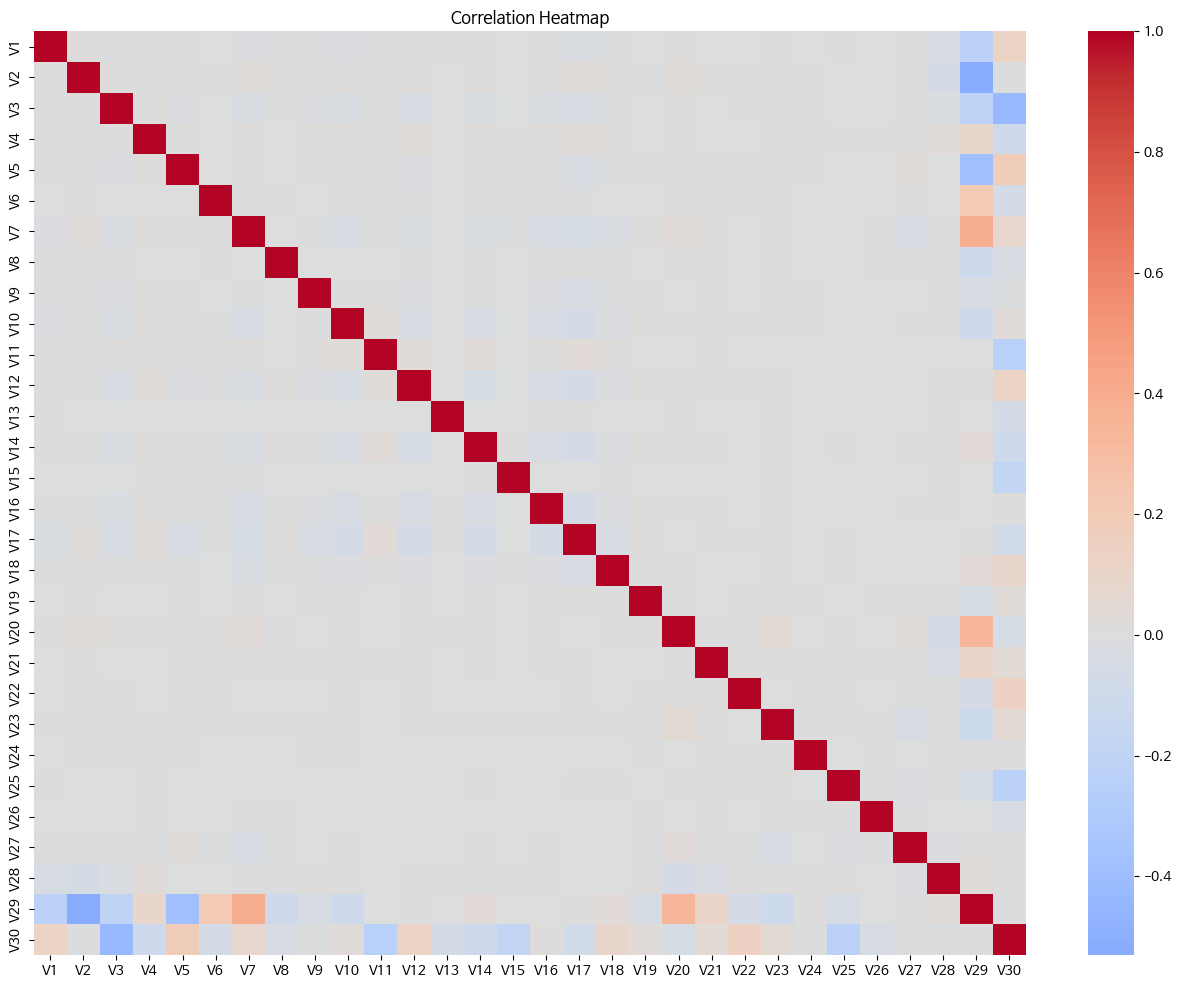

In [99]:
corr = train[features].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.show()

변수 간 상관관계를 확인한 결과, 대부분의 변수쌍은 상관계수가 0에 가까워 강한 선형 상관관계가 거의 나타나지 않았다. 따라서 변수 간 중복 정보가 크지 않은 것으로 보이며, 일부 변수와 V29·V30 사이에서만 상대적으로 약한 상관관계가 관찰되었다.

In [100]:
class_corr = val[feature_cols + ['Class']].corr()['Class'].drop('Class')

class_corr.sort_values().sort_values(ascending=False)

,Class
V11,0.142082
V4,0.126146
V2,0.096823
V8,0.038359
V19,0.024223
V22,0.016996
V20,0.015873
V26,0.005371
V23,0.005015
V13,0.001800


Class와 각 변수 간 상관관계를 분석한 결과, V17, V14, V12, V10, V7, V3 등이 비교적 큰 음의 상관을 보였으며, 이는 사기 거래에서 해당 변수들의 값이 정상 거래보다 낮게 나타난다는 것을 의미한다. 반대로 V11, V4, V2 등은 상대적으로 양의 상관을 보였다. 다만 절대 상관계수의 최대값도 약 0.29 수준으로 매우 강한 선형관계는 아니므로, 단일 변수보다는 여러 변수의 조합을 통해 사기 거래를 탐지하는 것이 적절할 것으로 판단된다.

##2-6. EDA 종합 요약
EDA 결과, 데이터에는 결측치가 없고 전체 행 기준 중복도 존재하지 않았다. 대부분의 변수는 0 부근에 값이 집중되어 있었으나 일부 변수에서는 긴 꼬리와 극단값이 확인되었다. Validation 데이터는 정상 거래 99.89%, 사기 거래 0.11%로 매우 심한 클래스 불균형을 보였다. 정상/사기 거래별 분포를 비교한 결과 V3, V14, V7, V10, V17, V12 등에서 뚜렷한 차이가 나타났으며, Class와의 상관관계에서도 동일 변수들이 상대적으로 높은 절대 상관을 보였다. 따라서 이후 모델링에서는 클래스 불균형을 고려하고, 여러 변수의 조합을 활용한 이상 탐지 접근이 필요하다.

# 3. 데이터 전처리

**[전처리 방향]**
- 결측치·전체 행 중복이 없으므로 결측 처리/중복 제거는 하지 않는다.
- V1~V30 기준 동일 특성값 245건은 서로 다른 거래일 수 있어 유지한다.
- 극단값은 사기 거래의 단서일 수 있으므로 제거하지 않는다.
- 'ID'는 식별자일 뿐이므로 모델 입력에서 제외한다.
- train에는 'Class'가 없으므로 train은 비지도 학습용, val은 성능 평가·임계값 조정용으로 사용한다.
- 모델에 따라 원본 / StandardScaler / RobustScaler 데이터를 선택해 사용할 수 있도록 준비한다.

## 3-1. 입력 변수(X)와 타깃(y) 분리

In [101]:
import numpy as np
import pandas as pd

feature_cols = [f'V{i}' for i in range(1, 31)] # ID 제외

X_train = train[feature_cols].copy()
X_val   = val[feature_cols].copy()
y_val   = val['Class'].copy()
X_test  = test[feature_cols].copy()

test_id = test['ID'].copy()

print('X_train:', X_train.shape)
print('X_val  :', X_val.shape, '| y_val:', y_val.shape)
print('X_test :', X_test.shape)

X_train: (113842, 30)
X_val  : (28462, 30) | y_val: (28462,)
X_test : (142503, 30)


## 3-2. 데이터셋 간 정합성 확인

In [102]:
# 세 데이터셋의 변수 구성/순서가 동일한지
print('컬럼 순서 일치:', list(X_train.columns) == list(X_val.columns) == list(X_test.columns))

# 모든 입력 변수가 수치형인지
print('모두 수치형:', all(pd.api.types.is_numeric_dtype(X_train[c]) for c in feature_cols))

# 무한대 값 존재 여부 (결측치는 EDA에서 0건 확인)
for name, df in [('train', X_train), ('val', X_val), ('test', X_test)]:
    print(f'{name} inf 개수:', np.isinf(df.values).sum())

# 제출 파일 ID 순서와 test ID 순서가 같은지
print('제출 ID 순서 일치:', (sample_submission['ID'].values == test_id.values).all())

컬럼 순서 일치: True
모두 수치형: True
train inf 개수: 0
val inf 개수: 0
test inf 개수: 0
제출 ID 순서 일치: True


## 3-3. 스케일링

극단값을 제거하지 않기로 했으므로, 평균·표준편차 대신 중앙값·IQR을 쓰는 RobustScaler도 함께 준비해 비교한다.

> 스케일러는 train에만 fit하고 val/test에는 transform만 적용한다. (val/test 정보가 학습에 섞이는 데이터 누수 방지)

In [103]:
from sklearn.preprocessing import StandardScaler, RobustScaler

def scale_data(scaler, X_tr, X_va, X_te):
    """train으로 fit한 scaler를 train/val/test에 적용해 DataFrame으로 반환"""
    scaler.fit(X_tr)
    to_df = lambda X: pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)
    return to_df(X_tr), to_df(X_va), to_df(X_te)

std_scaler = StandardScaler()
X_train_std, X_val_std, X_test_std = scale_data(std_scaler, X_train, X_val, X_test)

rob_scaler = RobustScaler()
X_train_rob, X_val_rob, X_test_rob = scale_data(rob_scaler, X_train, X_val, X_test)

print('StandardScaler 적용 완료:', X_train_std.shape, X_val_std.shape, X_test_std.shape)
print('RobustScaler   적용 완료:', X_train_rob.shape, X_val_rob.shape, X_test_rob.shape)

StandardScaler 적용 완료: (113842, 30) (28462, 30) (142503, 30)
RobustScaler   적용 완료: (113842, 30) (28462, 30) (142503, 30)


### 3-3-1. 스케일링 결과 확인

In [104]:
# train 기준: StandardScaler는 평균 0 / 표준편차 1, RobustScaler는 중앙값 0 / IQR 1 근처가 되어야 함
check = pd.DataFrame({
    'std_mean':   X_train_std.mean(),
    'std_std':    X_train_std.std(),
    'rob_median': X_train_rob.median(),
    'rob_IQR':    X_train_rob.quantile(0.75) - X_train_rob.quantile(0.25),
})
check.round(3)

,std_mean,std_std,rob_median,rob_IQR
V1,0.0,1.0,0.0,1.0
V2,-0.0,1.0,0.0,1.0
V3,0.0,1.0,0.0,1.0
V4,-0.0,1.0,0.0,1.0
V5,0.0,1.0,0.0,1.0
V6,0.0,1.0,0.0,1.0
V7,0.0,1.0,0.0,1.0
V8,0.0,1.0,-0.0,1.0
V9,0.0,1.0,0.0,1.0
V10,0.0,1.0,0.0,1.0


In [105]:
# train에 fit한 기준이 val/test에도 비슷하게 적용되는지 (분포 이동 여부) 확인
shift = pd.DataFrame({
    'train_mean': X_train_std.mean(),
    'val_mean':   X_val_std.mean(),
    'test_mean':  X_test_std.mean(),
    'train_std':  X_train_std.std(),
    'val_std':    X_val_std.std(),
    'test_std':   X_test_std.std(),
})
shift.round(3)

,train_mean,val_mean,test_mean,train_std,val_std,test_std
V1,0.0,0.002,-0.001,1.0,0.990,1.010
V2,-0.0,0.000,-0.002,1.0,0.972,1.006
V3,0.0,-0.006,-0.012,1.0,1.002,1.025
V4,-0.0,0.004,0.005,1.0,0.995,1.006
V5,0.0,-0.003,-0.000,1.0,0.976,1.023
V6,0.0,-0.017,-0.004,1.0,0.971,1.008
V7,0.0,-0.000,-0.010,1.0,0.968,1.060
V8,0.0,0.010,0.002,1.0,0.931,1.028
V9,0.0,-0.003,0.004,1.0,0.996,1.007
V10,0.0,-0.007,-0.008,1.0,1.012,1.030


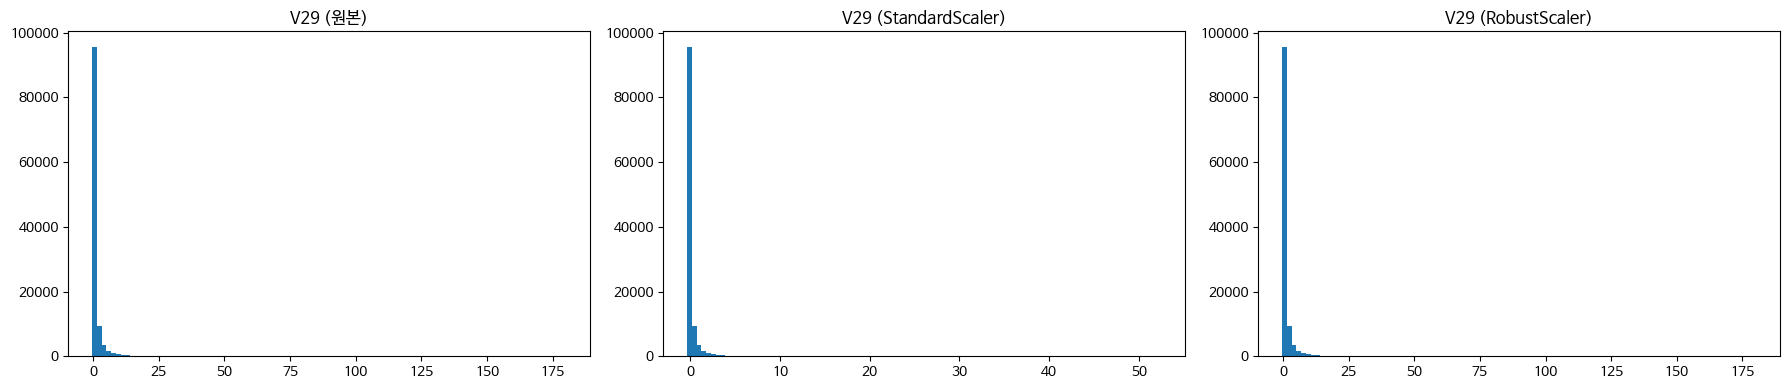

In [106]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# 나눔 폰트 설치
!apt-get -qq -y install fonts-nanum

font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fe = fm.FontEntry(
    fname=font_path,
    name='NanumBarunGothic'
)
fm.fontManager.ttflist.insert(0, fe)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 치우침이 가장 컸던 V29의 스케일링 전후 비교
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(X_train['V29'], bins=100);      axes[0].set_title('V29 (원본)')
axes[1].hist(X_train_std['V29'], bins=100);  axes[1].set_title('V29 (StandardScaler)')
axes[2].hist(X_train_rob['V29'], bins=100);  axes[2].set_title('V29 (RobustScaler)')
plt.tight_layout()
plt.show()

스케일링은 값의 위치와 크기만 바꿀 뿐 분포의 모양(치우침, 극단값)은 그대로 유지한다. 따라서 극단값이 담고 있는 이상 신호는 보존되면서 변수 간 크기 차이만 맞춰진다.

> 참고: 한글 제목이 깨지면 `plt.rcParams['font.family']` 설정 또는 영문 제목으로 바꿔서 실행.

## 3-4. 클래스 불균형 정보 정리

train에는 라벨이 없으므로 오버샘플링(SMOTE 등)이나 언더샘플링은 적용할 수 없다.
대신 val에서 확인한 사기 비율을 이상 탐지 모델의 이상치 비율 하이퍼파라미터로 활용한다.

- Isolation Forest / LOF → 'contamination'
- One-Class SVM → 'nu'

In [107]:
n_fraud = int(y_val.sum())
n_total = len(y_val)
fraud_ratio = n_fraud / n_total

print(f'Validation 사기 거래: {n_fraud}건 / {n_total}건')
print(f'사기 비율: {fraud_ratio:.6f}  ({fraud_ratio*100:.3f}%)')

Validation 사기 거래: 30건 / 28462건
사기 비율: 0.001054  (0.105%)


평가 지표는 Accuracy 대신 Precision, Recall, F1-score(특히 Macro F1)를 사용한다.
모든 거래를 정상으로 예측해도 Accuracy는 약 99.89%가 나오기 때문이다.

## 3-5. 모델별 사용할 데이터셋 정리


In [108]:
datasets = {
    'raw':      (X_train,     X_val,     X_test),
    'standard': (X_train_std, X_val_std, X_test_std),
    'robust':   (X_train_rob, X_val_rob, X_test_rob),
}

for name, (tr, va, te) in datasets.items():
    print(f'[{name:8s}] train {tr.shape} | val {va.shape} | test {te.shape}')

[raw     ] train (113842, 30) | val (28462, 30) | test (142503, 30)
[standard] train (113842, 30) | val (28462, 30) | test (142503, 30)
[robust  ] train (113842, 30) | val (28462, 30) | test (142503, 30)


## 3-6. 전처리 요약

- 'ID'를 제외한 V1~V30 30개 변수를 모델 입력으로 사용하고, test의 'ID'는 제출용으로 따로 보관하였다.
- 결측치·전체 행 중복이 없어 별도 처리는 하지 않았으며, 동일 특성값 행과 극단값은 이상 탐지에 필요한 정보일 수 있어 유지하였다.
- 변수 간 스케일 차이를 고려해 train 기준으로 fit한 StandardScaler·RobustScaler 데이터를 만들고, 스케일 영향이 없는 모델용으로 원본 데이터도 함께 준비하였다.
- train에 라벨이 없어 샘플링 기반 불균형 처리는 불가능하므로, val의 사기 비율(약 0.105%)을 이상 탐지 모델의 'contamination'/'nu' 값으로 활용할 예정이다.
- 이후 모델링에서는 train으로 비지도 학습 → val로 Precision/Recall/F1 평가 및 임계값 조정 → test 예측 순서로 진행한다.

## 4. 모델링 A

In [109]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

fraud_ratio = y_val.mean()

print('Validation fraud ratio:', fraud_ratio)
print('Fraud count:', y_val.sum())

Validation fraud ratio: 0.0010540369615627855
Fraud count: 30


In [110]:
def find_best_threshold(y_true, anomaly_scores):
    y_true = np.asarray(y_true).astype(int)
    anomaly_scores = np.asarray(anomaly_scores, dtype=float)

    order = np.argsort(-anomaly_scores)
    y_sorted = y_true[order]
    score_sorted = anomaly_scores[order]

    tp_cum = np.cumsum(y_sorted == 1)
    fp_cum = np.cumsum(y_sorted == 0)

    total_pos = np.sum(y_true == 1)
    total_neg = np.sum(y_true == 0)

    group_end = np.r_[
        np.where(score_sorted[:-1] != score_sorted[1:])[0],
        len(score_sorted) - 1
    ]

    tp = tp_cum[group_end]
    fp = fp_cum[group_end]
    fn = total_pos - tp
    tn = total_neg - fp

    f1_pos = np.divide(
        2 * tp,
        2 * tp + fp + fn,
        out=np.zeros_like(tp, dtype=float),
        where=(2 * tp + fp + fn) != 0
    )

    f1_neg = np.divide(
        2 * tn,
        2 * tn + fp + fn,
        out=np.zeros_like(tn, dtype=float),
        where=(2 * tn + fp + fn) != 0
    )

    macro_f1 = (f1_pos + f1_neg) / 2

    best_idx = np.argmax(macro_f1)
    best_threshold = score_sorted[group_end[best_idx]]
    best_macro_f1 = macro_f1[best_idx]

    return best_threshold, best_macro_f1

In [111]:
def evaluate_anomaly_model(model_name, y_true, anomaly_scores, threshold):
    y_pred = (anomaly_scores >= threshold).astype(int)

    result = {
        'model': model_name,
        'threshold': threshold,
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'fraud_precision': precision_score(y_true, y_pred, zero_division=0),
        'fraud_recall': recall_score(y_true, y_pred, zero_division=0),
        'fraud_f1': f1_score(y_true, y_pred, zero_division=0),
        'average_precision': average_precision_score(y_true, anomaly_scores),
        'predicted_fraud': y_pred.sum()
    }

    print(f'[{model_name}]')
    print('Threshold:', threshold)
    print('Predicted fraud:', y_pred.sum())
    print('Macro F1:', result['macro_f1'])
    print('Average Precision:', result['average_precision'])
    print()
    print(confusion_matrix(y_true, y_pred))
    print()
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))

    return result, y_pred


## 4.1 Isolation Forest

In [112]:
from sklearn.ensemble import IsolationForest

if_model = IsolationForest(
    n_estimators=300,
    max_samples='auto',
    contamination=fraud_ratio,
    random_state=42,
    n_jobs=-1
)

if_model.fit(X_train)

IsolationForest(contamination=np.float64(0.0010540369615627855),
                n_estimators=300, n_jobs=-1, random_state=42)

sklearn의 기본 contamination 기준 예측 결과

In [113]:
if_default_pred = (if_model.predict(X_val) == -1).astype(int)

print('Isolation Forest - Default Threshold')
print('Predicted fraud:', if_default_pred.sum())
print('Macro F1:', f1_score(y_val, if_default_pred, average='macro'))
print()
print(confusion_matrix(y_val, if_default_pred))
print()
print(classification_report(y_val, if_default_pred, digits=4, zero_division=0))

Isolation Forest - Default Threshold
Predicted fraud: 24
Macro F1: 0.703422360288898

[[28419    13]
 [   19    11]]

              precision    recall  f1-score   support

           0     0.9993    0.9995    0.9994     28432
           1     0.4583    0.3667    0.4074        30

    accuracy                         0.9989     28462
   macro avg     0.7288    0.6831    0.7034     28462
weighted avg     0.9988    0.9989    0.9988     28462



anomaly score (실제 사용)

In [114]:
if_val_scores = -if_model.decision_function(X_val)

if_threshold, if_best_macro_f1 = find_best_threshold(
    y_val,
    if_val_scores
)

print('Best threshold:', if_threshold)
print('Best Macro F1:', if_best_macro_f1)

Best threshold: 0.004520987946239785
Best Macro F1: 0.7072746231706779


In [115]:
if_result, if_val_pred = evaluate_anomaly_model(
    'Isolation Forest',
    y_val,
    if_val_scores,
    if_threshold
)

[Isolation Forest]
Threshold: 0.004520987946239785
Predicted fraud: 23
Macro F1: 0.7072746231706779
Average Precision: 0.22572644763630084

[[28420    12]
 [   19    11]]

              precision    recall  f1-score   support

           0     0.9993    0.9996    0.9995     28432
           1     0.4783    0.3667    0.4151        30

    accuracy                         0.9989     28462
   macro avg     0.7388    0.6831    0.7073     28462
weighted avg     0.9988    0.9989    0.9988     28462



## 4.2 LOF (Local Outlier Factor)

LOF는 한 점과 주변 이웃들의 local density 차이를 이용하기 때문에 변수 scale에 영향을 많이 받는다. 따라서 여기서는 X_train_std, X_val_std, X_test_std를 사용

novelty=True 상태인데 novelty detection 방식으로 사용해야 하기 때문에 decision_function()과 predict()는 train이 아니라 새로운 val/test에만 적용

In [116]:
from sklearn.neighbors import LocalOutlierFactor

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=fraud_ratio,
    novelty=True,
    n_jobs=-1
)

lof_model.fit(X_train_std)

LocalOutlierFactor(contamination=np.float64(0.0010540369615627855), n_jobs=-1,
                   novelty=True)

기본 threshold 결과 확인

In [117]:
lof_default_pred = (lof_model.predict(X_val_std) == -1).astype(int)

print('LOF - Default Threshold')
print('Predicted fraud:', lof_default_pred.sum())
print('Macro F1:', f1_score(y_val, lof_default_pred, average='macro'))
print()
print(confusion_matrix(y_val, lof_default_pred))
print()
print(classification_report(y_val, lof_default_pred, digits=4, zero_division=0))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


LOF - Default Threshold
Predicted fraud: 31
Macro F1: 0.49946362309410336

[[28401    31]
 [   30     0]]

              precision    recall  f1-score   support

           0     0.9989    0.9989    0.9989     28432
           1     0.0000    0.0000    0.0000        30

    accuracy                         0.9979     28462
   macro avg     0.4995    0.4995    0.4995     28462
weighted avg     0.9979    0.9979    0.9979     28462



decision_function()이 낮을수록 이상치이므로 부호를 반대로 바꿔야한다

In [118]:
lof_val_scores = -lof_model.decision_function(X_val_std)

lof_threshold, lof_best_macro_f1 = find_best_threshold(
    y_val,
    lof_val_scores
)

print('Best threshold:', lof_threshold)
print('Best Macro F1:', lof_best_macro_f1)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Best threshold: -1.7284330255635387
Best Macro F1: 0.5020529923900806


In [119]:
lof_result, lof_val_pred = evaluate_anomaly_model(
    'LOF',
    y_val,
    lof_val_scores,
    lof_threshold
)

[LOF]
Threshold: -1.7284330255635387
Predicted fraud: 345
Macro F1: 0.5020529923900806
Average Precision: 0.0020398128189050924

[[28089   343]
 [   28     2]]

              precision    recall  f1-score   support

           0     0.9990    0.9879    0.9934     28432
           1     0.0058    0.0667    0.0107        30

    accuracy                         0.9870     28462
   macro avg     0.5024    0.5273    0.5021     28462
weighted avg     0.9980    0.9870    0.9924     28462



test도 동일하게 적용

In [120]:
lof_test_scores = -lof_model.decision_function(X_test_std)

lof_test_pred = (lof_test_scores >= lof_threshold).astype(int)

print('Test predicted fraud:', lof_test_pred.sum())
print('Test predicted fraud ratio:', lof_test_pred.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Test predicted fraud: 1650
Test predicted fraud ratio: 0.011578703606239868


## 4.3 두 모델 비교

In [121]:
results = pd.DataFrame([
    if_result,
    lof_result
])

results = results.sort_values(
    'macro_f1',
    ascending=False
).reset_index(drop=True)

results

,model,threshold,macro_f1,fraud_precision,fraud_recall,fraud_f1,average_precision,predicted_fraud
0,Isolation Forest,0.004521,0.707275,0.478261,0.366667,0.415094,0.225726,23
1,LOF,-1.728433,0.502053,0.005797,0.066667,0.010667,0.002040,345


Isolation Forest와 LOF를 비교한 결과, Isolation Forest가 validation 기준 Macro F1 0.7073으로 LOF의 0.5021보다 높은 성능을 보였다. Isolation Forest는 총 23건을 이상 거래로 탐지했으며, 실제 사기 거래 precision 0.4783 (30개 중 약 11개 탐지), recall 0.3667을 기록하였다. 반면 LOF는 345건을 이상 거래로 분류했지만 실제 사기 거래는 2건만 탐지하여 다수의 false positive가 발생하였다. 따라서 Isolation Forest가 데이터의 이상 거래 구조를 더 효과적으로 포착하는 것으로 판단하였다.

## 5. 모델링 B

## 5.1 PCA 복원 오차

In [122]:
from sklearn.decomposition import PCA

def pca_score(model, X):
    X_back = model.inverse_transform(model.transform(X))
    return ((X.values - X_back) ** 2).sum(axis=1)

# 주성분 개수별로 val Macro F1 비교
best_n = None
best_f1 = 0

for n in [5, 10, 15, 20, 25]:
    p = PCA(n_components=n, random_state=42)
    p.fit(X_train_std)
    s = pca_score(p, X_val_std)
    th, f1 = find_best_threshold(y_val, s)
    print('주성분', n, '개 -> Macro F1:', round(f1, 4))
    if f1 > best_f1:
        best_f1 = f1
        best_n = n

print('선택된 주성분 개수:', best_n)

주성분 5 개 -> Macro F1: 0.7437
주성분 10 개 -> Macro F1: 0.7498
주성분 15 개 -> Macro F1: 0.7498
주성분 20 개 -> Macro F1: 0.7498
주성분 25 개 -> Macro F1: 0.745
선택된 주성분 개수: 10


In [123]:
pca = PCA(n_components=best_n, random_state=42)
pca.fit(X_train_std)

pca_train_scores = pca_score(pca, X_train_std)
pca_val_scores = pca_score(pca, X_val_std)
pca_test_scores = pca_score(pca, X_test_std)

pca_threshold, pca_best_macro_f1 = find_best_threshold(y_val, pca_val_scores)
pca_result, pca_val_pred = evaluate_anomaly_model('PCA', y_val, pca_val_scores, pca_threshold)

[PCA]
Threshold: 1431.2121301283657
Predicted fraud: 14
Macro F1: 0.7498066104078762
Average Precision: 0.36543442386065067

[[28429     3]
 [   19    11]]

              precision    recall  f1-score   support

           0     0.9993    0.9999    0.9996     28432
           1     0.7857    0.3667    0.5000        30

    accuracy                         0.9992     28462
   macro avg     0.8925    0.6833    0.7498     28462
weighted avg     0.9991    0.9992    0.9991     28462



## 5.2 Autoencoder

In [124]:
from sklearn.neural_network import MLPRegressor

def ae_score(model, X):
    X_back = model.predict(X)
    return ((X.values - X_back) ** 2).sum(axis=1)

# 구조(은닉층) 비교
structures = [(20, 10, 20), (20, 5, 20), (24, 12, 6, 12, 24)]

best_ae = None
best_ae_f1 = 0

for layers in structures:
    ae_try = MLPRegressor(hidden_layer_sizes=layers, activation='relu',
                          max_iter=50, early_stopping=True, random_state=42)
    ae_try.fit(X_train_std, X_train_std)
    s = ae_score(ae_try, X_val_std)
    th, f1 = find_best_threshold(y_val, s)
    print(layers, '-> Macro F1:', round(f1, 4))
    if f1 > best_ae_f1:
        best_ae_f1 = f1
        best_ae = ae_try
        best_layers = layers

print('선택된 구조:', best_layers)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


(20, 10, 20) -> Macro F1: 0.5722


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


(20, 5, 20) -> Macro F1: 0.5719
(24, 12, 6, 12, 24) -> Macro F1: 0.6932
선택된 구조: (24, 12, 6, 12, 24)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


In [125]:
ae_train_scores = ae_score(best_ae, X_train_std)
ae_val_scores = ae_score(best_ae, X_val_std)
ae_test_scores = ae_score(best_ae, X_test_std)

ae_threshold, ae_best_macro_f1 = find_best_threshold(y_val, ae_val_scores)
ae_result, ae_val_pred = evaluate_anomaly_model('Autoencoder', y_val, ae_val_scores, ae_threshold)

[Autoencoder]
Threshold: 147.46690052761585
Predicted fraud: 32
Macro F1: 0.6932142447873233
Average Precision: 0.29495184240951894

[[28412    20]
 [   18    12]]

              precision    recall  f1-score   support

           0     0.9994    0.9993    0.9993     28432
           1     0.3750    0.4000    0.3871        30

    accuracy                         0.9987     28462
   macro avg     0.6872    0.6996    0.6932     28462
weighted avg     0.9987    0.9987    0.9987     28462



## 5.3 One-Class SVM

In [126]:
from sklearn.svm import OneClassSVM

sample_idx = X_train_std.sample(10000, random_state=42).index
X_train_sample = X_train_std.loc[sample_idx]

ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.01)
ocsvm.fit(X_train_sample)

ocsvm_train_scores = -ocsvm.decision_function(X_train_sample)
ocsvm_val_scores = -ocsvm.decision_function(X_val_std)
ocsvm_test_scores = -ocsvm.decision_function(X_test_std)

ocsvm_threshold, ocsvm_best_macro_f1 = find_best_threshold(y_val, ocsvm_val_scores)
ocsvm_result, ocsvm_val_pred = evaluate_anomaly_model('One-Class SVM', y_val, ocsvm_val_scores, ocsvm_threshold)

[One-Class SVM]
Threshold: 0.5658279666710221
Predicted fraud: 77
Macro F1: 0.6207825122762554
Average Precision: 0.11397613699052933

[[28368    64]
 [   17    13]]

              precision    recall  f1-score   support

           0     0.9994    0.9977    0.9986     28432
           1     0.1688    0.4333    0.2430        30

    accuracy                         0.9972     28462
   macro avg     0.5841    0.7155    0.6208     28462
weighted avg     0.9985    0.9972    0.9978     28462



## 5.4 전체 모델 비교

In [127]:
results_all = pd.DataFrame([if_result, lof_result, pca_result, ae_result, ocsvm_result])
results_all = results_all.sort_values('macro_f1', ascending=False).reset_index(drop=True)
results_all

,model,threshold,macro_f1,fraud_precision,fraud_recall,fraud_f1,average_precision,predicted_fraud
0,PCA,1431.212130,0.749807,0.785714,0.366667,0.500000,0.365434,14
1,Isolation Forest,0.004521,0.707275,0.478261,0.366667,0.415094,0.225726,23
2,Autoencoder,147.466901,0.693214,0.375000,0.400000,0.387097,0.294952,32
3,One-Class SVM,0.565828,0.620783,0.168831,0.433333,0.242991,0.113976,77
4,LOF,-1.728433,0.502053,0.005797,0.066667,0.010667,0.002040,345


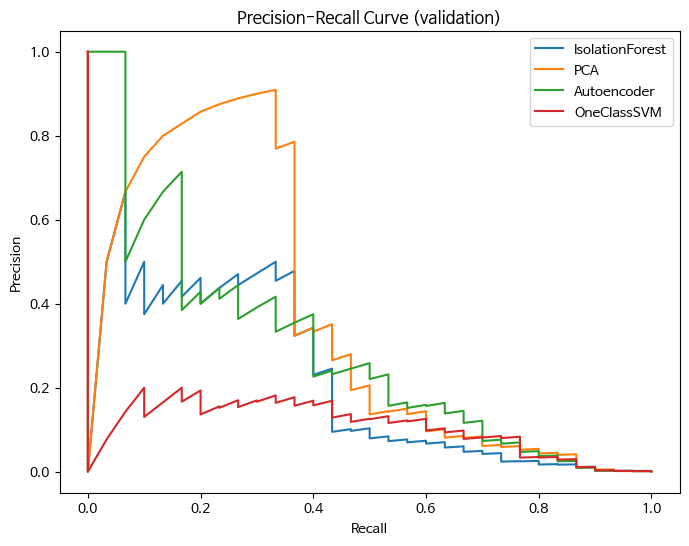

In [128]:
from sklearn.metrics import precision_recall_curve

# 모델별 이상 점수
model_scores = {
    'IsolationForest': (-if_model.decision_function(X_train),
                        -if_model.decision_function(X_val),
                        -if_model.decision_function(X_test)),
    'PCA': (pca_train_scores, pca_val_scores, pca_test_scores),
    'Autoencoder': (ae_train_scores, ae_val_scores, ae_test_scores),
    'OneClassSVM': (ocsvm_train_scores, ocsvm_val_scores, ocsvm_test_scores),
}

plt.figure(figsize=(8, 6))
for name, (tr, va, te) in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_val, va)
    plt.plot(recall, precision, label=name)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (validation)')
plt.legend()
plt.show()

## 5.5 점수 앙상블

In [129]:
def to_percentile(train_scores, scores):
    sorted_train = np.sort(train_scores)
    return np.searchsorted(sorted_train, scores) / len(sorted_train)

# 모델별 점수를 0~1 위치값으로 변환
pct_scores = {}
for name, (tr, va, te) in model_scores.items():
    pct_scores[name] = (to_percentile(tr, va), to_percentile(tr, te))

# 조합별로 평균 낸 뒤 val Macro F1 비교
combos = [
    ['IsolationForest', 'Autoencoder'],
    ['IsolationForest', 'PCA'],
    ['IsolationForest', 'PCA', 'Autoencoder'],
    ['IsolationForest', 'PCA', 'Autoencoder', 'OneClassSVM'],
]

for combo in combos:
    ens_val = np.mean([pct_scores[m][0] for m in combo], axis=0)
    th, f1 = find_best_threshold(y_val, ens_val)
    print(combo, '-> Macro F1:', round(f1, 4))

['IsolationForest', 'Autoencoder'] -> Macro F1: 0.6816
['IsolationForest', 'PCA'] -> Macro F1: 0.7338
['IsolationForest', 'PCA', 'Autoencoder'] -> Macro F1: 0.7125
['IsolationForest', 'PCA', 'Autoencoder', 'OneClassSVM'] -> Macro F1: 0.7125


## 5.6 최종 모델 선택 및 안정성 확인

### 최종 후보 비교
PCA 단독, IF+PCA, IF+PCA+Autoencoder 세 후보의 임계값 안정성을 비교했다.

In [130]:
#최종 후보 비교
candidates = [
    ['PCA'],
    ['IsolationForest', 'PCA'],
    ['IsolationForest', 'PCA', 'Autoencoder'],
]

for combo in candidates:
    val_s = np.mean([pct_scores[m][0] for m in combo], axis=0)
    sorted_s = np.sort(val_s)[::-1]
    print(combo)
    for k in [15, 20, 25, 30, 40, 50]:
        th = sorted_s[k - 1]
        pred = (val_s >= th).astype(int)
        print('  상위', k, '건 -> Macro F1:', round(f1_score(y_val, pred, average='macro'), 4))
    print()

['PCA']
  상위 15 건 -> Macro F1: 0.7442
  상위 20 건 -> Macro F1: 0.7198
  상위 25 건 -> Macro F1: 0.6997
  상위 30 건 -> Macro F1: 0.683
  상위 40 건 -> Macro F1: 0.6827
  상위 50 건 -> Macro F1: 0.6745

['IsolationForest', 'PCA']
  상위 15 건 -> Macro F1: 0.6998
  상위 20 건 -> Macro F1: 0.7198
  상위 25 건 -> Macro F1: 0.6997
  상위 30 건 -> Macro F1: 0.6964
  상위 40 건 -> Macro F1: 0.6853
  상위 50 건 -> Macro F1: 0.662

['IsolationForest', 'PCA', 'Autoencoder']
  상위 15 건 -> Macro F1: 0.6775
  상위 20 건 -> Macro F1: 0.6997
  상위 25 건 -> Macro F1: 0.6815
  상위 30 건 -> Macro F1: 0.6997
  상위 40 건 -> Macro F1: 0.6853
  상위 50 건 -> Macro F1: 0.6745



In [131]:
final_models = ['IsolationForest', 'PCA']

final_val = np.mean([pct_scores[m][0] for m in final_models], axis=0)
final_test = np.mean([pct_scores[m][1] for m in final_models], axis=0)

final_threshold, final_macro_f1 = find_best_threshold(y_val, final_val)
final_result, final_val_pred = evaluate_anomaly_model('Final', y_val, final_val, final_threshold)

[Final]
Threshold: 0.9994202491171975
Predicted fraud: 17
Macro F1: 0.7338227806999726
Average Precision: 0.37598106738042486

[[28426     6]
 [   19    11]]

              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     28432
           1     0.6471    0.3667    0.4681        30

    accuracy                         0.9991     28462
   macro avg     0.8232    0.6832    0.7338     28462
weighted avg     0.9990    0.9991    0.9990     28462



In [132]:
# val 과적합 점검
sorted_val = np.sort(final_val)[::-1]

for k in [15, 20, 25, 30, 40, 50, 60]:
    th = sorted_val[k - 1]
    pred = (final_val >= th).astype(int)
    print('상위', k, '건을 사기로 예측 -> Macro F1:', round(f1_score(y_val, pred, average='macro'), 4))

상위 15 건을 사기로 예측 -> Macro F1: 0.6998
상위 20 건을 사기로 예측 -> Macro F1: 0.7198
상위 25 건을 사기로 예측 -> Macro F1: 0.6997
상위 30 건을 사기로 예측 -> Macro F1: 0.6964
상위 40 건을 사기로 예측 -> Macro F1: 0.6853
상위 50 건을 사기로 예측 -> Macro F1: 0.662
상위 60 건을 사기로 예측 -> Macro F1: 0.6439


## 5.7 test 예측 및 제출 파일

In [133]:
test_pred = (final_test >= final_threshold).astype(int)

print('val 사기 예측 비율 :', final_val_pred.mean())
print('test 사기 예측 비율:', test_pred.mean())
print('test 사기 예측 건수:', test_pred.sum())

val 사기 예측 비율 : 0.0005972876115522451
test 사기 예측 비율: 0.0006596352357494228
test 사기 예측 건수: 94


In [134]:
print(sample_submission.columns)

submission = sample_submission.copy()
submission['Class'] = test_pred
submission.to_csv('/content/drive/MyDrive/[ESAA] OB 1조/프로젝트2/submission.csv', index=False)

print(submission['Class'].value_counts())
submission.head()

Index(['ID', 'Class'], dtype='object')
Class
0    142409
1        94
Name: count, dtype: int64


,ID,Class
0,AAAA0x1,0
1,AAAA0x2,0
2,AAAA0x5,0
3,AAAA0x7,0
4,AAAA0xc,0


## 6. 결론

- 평가 지표: 사기 비율이 약 0.1%라 Accuracy 대신 Macro F1과 Precision-Recall 곡선(Average Precision)으로 비교했다.
- 모델 비교: PCA(Macro F1 0.7498), Isolation Forest(0.7073), Autoencoder(0.6932), One-Class SVM(0.6208), LOF(0.5021) 순으로 성능이 높았다. PCA는 사기로 예측한 14건 중 11건이 실제 사기였고(precision 0.786), Average Precision도 0.365로 가장 높았다.
- PCA는 주성분 개수를 10~20개로 바꿔도 Macro F1이 0.7498로 같아 설정에 민감하지 않았다.
- LOF는 345건을 이상으로 분류했지만 실제 사기는 2건만 맞혀 false positive가 많았다. One-Class SVM도 77건 중 13건만 맞혀 정밀도가 낮았다.
- Autoencoder는 max_iter=50에서 수렴하지 못해 학습이 충분하지 않았을 가능성이 있다.
- 앙상블: Isolation Forest+PCA는 0.7338, Isolation Forest+PCA+Autoencoder는 0.7125로, 성능이 낮은 모델을 섞으면 오히려 낮아졌다.
- 최종 모델: Isolation Forest와 PCA의 이상 점수를 평균한 앙상블을 선택했다(Macro F1 0.7338, 사기 예측 17건 중 11건 적중). PCA 단독이 validation 최고점(0.7498)이었지만, 상위 15건 근처의 좁은 구간에서만 높고 예측 건수가 늘수록 0.7442에서 0.6745까지 꾸준히 낮아졌다. 반면 앙상블은 상위 20~40건 구간에서 0.685~0.720으로 비교적 안정적이었고, 트리 기반 고립(Isolation Forest)과 선형 복원 오차(PCA)처럼 방식이 다른 모델을 합쳐 val 30건에 대한 과적합 위험을 줄이고자 했다. Autoencoder를 추가한 앙상블은 어느 구간에서도 개선이 없어 제외했다.
- test 예측: 최종 모델로 test 142,503건 중 94건(약 0.066%)을 사기로 예측했고, 이는 val 예측 비율(약 0.060%)과 비슷한 수준이다.
- 한계: val의 사기 거래가 30건뿐이라 임계값과 주성분 개수를 val에 맞춰 고르는 과정에서 과적합될 수 있다. 상위 15~50건으로 임계값을 바꿔 확인했을 때 최종 모델의 Macro F1은 약 0.66~0.72 범위였고, 최적 임계값에서의 점수(0.7338)보다 낮을 수 있어 실제 test 성능은 이보다 낮을 수 있다.
- 개선 방향: Autoencoder 학습 횟수 확대 및 구조 탐색, V29 log 변환 후 재비교, 변수 선택, 앙상블 가중치 조정.